In [185]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

from sklearn.preprocessing import (
    MultiLabelBinarizer,
    OneHotEncoder
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import (
    LinearRegression,
    Ridge
)

from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

import warnings
warnings.filterwarnings("ignore")

In [186]:
model_df = pd.read_csv("../dataset/processed/model_dataset.csv")

print(model_df.shape)

model_df.head()

(5321, 19)


,budget,id,original_language,overview,revenue,runtime,profit,roi,franchise,release_year,release_month,release_quarter,release_season,genre_list,director,keyword_list,company_list,language_list,country_list
0,30000000,862,en,"Led by Woody, Andy's toys live happily in his ...",373554033.0,81.0,343554033.0,11.451801,1,1995,10,4,Fall,"['Animation', 'Comedy', 'Family']",John Lasseter,"['jealousy', 'toy', 'boy', 'friendship', 'frie...",['Pixar Animation Studios'],['English'],['United States of America']
1,65000000,8844,en,When siblings Judy and Peter discover an encha...,262797249.0,104.0,197797249.0,3.043035,0,1995,12,4,Winter,"['Adventure', 'Fantasy', 'Family']",Joe Johnston,"['board game', 'disappearance', ""based on chil...","['TriStar Pictures', 'Teitler Film', 'Intersco...","['English', 'Français']",['United States of America']
2,16000000,31357,en,"Cheated on, mistreated and stepped on, the wom...",81452156.0,127.0,65452156.0,4.090760,0,1995,12,4,Winter,"['Comedy', 'Drama', 'Romance']",Forest Whitaker,"['based on novel', 'interracial relationship',...",['Twentieth Century Fox Film Corporation'],['English'],['United States of America']
3,60000000,949,en,"Obsessive master thief, Neil McCauley leads a ...",187436818.0,170.0,127436818.0,2.123947,0,1995,12,4,Winter,"['Action', 'Crime', 'Drama', 'Thriller']",Michael Mann,"['robbery', 'detective', 'bank', 'obsession', ...","['Regency Enterprises', 'Forward Pass', 'Warne...","['English', 'Español']",['United States of America']
4,35000000,9091,en,International action superstar Jean Claude Van...,64350171.0,106.0,29350171.0,0.838576,0,1995,12,4,Winter,"['Action', 'Adventure', 'Thriller']",Peter Hyams,"['terrorist', 'hostage', 'explosive', 'vice pr...","['Universal Pictures', 'Imperial Entertainment...",['English'],['United States of America']


In [187]:
model_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5321 entries, 0 to 5320
Data columns (total 19 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   budget             5321 non-null   int64  
 1   id                 5321 non-null   int64  
 2   original_language  5321 non-null   str    
 3   overview           5310 non-null   str    
 4   revenue            5321 non-null   float64
 5   runtime            5320 non-null   float64
 6   profit             5321 non-null   float64
 7   roi                5321 non-null   float64
 8   franchise          5321 non-null   int64  
 9   release_year       5321 non-null   int64  
 10  release_month      5321 non-null   int64  
 11  release_quarter    5321 non-null   int64  
 12  release_season     5321 non-null   str    
 13  genre_list         5321 non-null   str    
 14  director           5316 non-null   str    
 15  keyword_list       5321 non-null   str    
 16  company_list       5321 non-null   

In [188]:
model_df.isnull().sum()

budget                0
id                    0
original_language     0
overview             11
revenue               0
runtime               1
profit                0
roi                   0
franchise             0
release_year          0
release_month         0
release_quarter       0
release_season        0
genre_list            0
director              5
keyword_list          0
company_list          0
language_list         0
country_list          0
dtype: int64

In [189]:
# ==========================================
# 4. Handle Missing Values
# ==========================================

model_df["overview"] = model_df["overview"].fillna("")
model_df["director"] = model_df["director"].fillna("Unknown")
model_df["runtime"] = model_df["runtime"].fillna(model_df["runtime"].median())

print(model_df.isnull().sum())

budget               0
id                   0
original_language    0
overview             0
revenue              0
runtime              0
profit               0
roi                  0
franchise            0
release_year         0
release_month        0
release_quarter      0
release_season       0
genre_list           0
director             0
keyword_list         0
company_list         0
language_list        0
country_list         0
dtype: int64


In [190]:
# ==========================================
# 5. Convert String Lists to Python Lists
# ==========================================

import ast

list_columns = [
    "genre_list",
    "keyword_list",
    "company_list",
    "language_list",
    "country_list"
]

for col in list_columns:
    model_df[col] = model_df[col].apply(ast.literal_eval)

print(type(model_df.loc[0, "genre_list"]))
print(model_df.loc[0, "genre_list"])

<class 'list'>
['Animation', 'Comedy', 'Family']


In [191]:
# ==========================================
# 6. Define Target Variable
# ==========================================

y = model_df["roi"]

print(y.head())

0    11.451801
1     3.043035
2     4.090760
3     2.123947
4     0.838576
Name: roi, dtype: float64


In [192]:
# ==========================================
# 7. Remove Leakage Columns
# ==========================================

X = model_df.drop(
    columns=[
        "id",
        "revenue",
        "profit",
        "roi"
    ]
)

print(X.columns)
print(X.shape)

Index(['budget', 'original_language', 'overview', 'runtime', 'franchise',
       'release_year', 'release_month', 'release_quarter', 'release_season',
       'genre_list', 'director', 'keyword_list', 'company_list',
       'language_list', 'country_list'],
      dtype='str')
(5321, 15)


In [193]:
# ==========================================
# 8. Model 1 - Budget Only
# ==========================================

X_budget = model_df[["budget"]]

print(X_budget.head())
print(X_budget.shape)

     budget
0  30000000
1  65000000
2  16000000
3  60000000
4  35000000
(5321, 1)


In [194]:
# ==========================================
# 9. Train-Test Split
# ==========================================

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_budget,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples :", X_train.shape)
print("Testing samples  :", X_test.shape)

Training samples : (4256, 1)
Testing samples  : (1065, 1)


In [195]:
# ==========================================
# 10. Linear Regression
# ==========================================

from sklearn.linear_model import LinearRegression

lr = LinearRegression()

lr.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [196]:
# ==========================================
# 11. Predict ROI
# ==========================================

y_pred = lr.predict(X_test)

print(y_pred[:10])

[2.85980058 3.4816894  2.85980058 3.15593811 3.5211744  3.46132199
 3.15593811 2.9979981  3.43233314 3.33362063]


In [197]:
# ==========================================
# 12. Model Evaluation
# ==========================================

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_test, y_pred)
)

r2 = r2_score(y_test, y_pred)

print(f"MAE  : {mae:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"R²   : {r2:.4f}")

MAE  : 3.5915
RMSE : 6.7992
R²   : 0.0165


In [198]:
# ==========================================
# 13. Model 2 - Basic Movie Features
# ==========================================

X2 = model_df[
    [
        "budget",
        "runtime",
        "franchise",
        "release_year",
        "release_month",
        "release_season",
        "original_language"
    ]
]

print(X2.head())
print(X2.shape)

     budget  runtime  franchise  release_year  release_month release_season  \
0  30000000     81.0          1          1995             10           Fall   
1  65000000    104.0          0          1995             12         Winter   
2  16000000    127.0          0          1995             12         Winter   
3  60000000    170.0          0          1995             12         Winter   
4  35000000    106.0          0          1995             12         Winter   

  original_language  
0                en  
1                en  
2                en  
3                en  
4                en  
(5321, 7)


In [199]:
# ==========================================
# 14. One-Hot Encode Categorical Features
# ==========================================

X2 = pd.get_dummies(
    X2,
    columns=[
        "original_language",
        "release_season"
    ],
    drop_first=True
)

print(X2.head())
print(X2.shape)

     budget  runtime  franchise  release_year  release_month  \
0  30000000     81.0          1          1995             10   
1  65000000    104.0          0          1995             12   
2  16000000    127.0          0          1995             12   
3  60000000    170.0          0          1995             12   
4  35000000    106.0          0          1995             12   

   original_language_bm  original_language_ca  original_language_cn  \
0                 False                 False                 False   
1                 False                 False                 False   
2                 False                 False                 False   
3                 False                 False                 False   
4                 False                 False                 False   

   original_language_da  original_language_de  ...  original_language_te  \
0                 False                 False  ...                 False   
1                 False             

In [200]:
# ==========================================
# 15. Train-Test Split
# ==========================================

X_train2, X_test2, y_train2, y_test2 = train_test_split(
    X2,
    y,
    test_size=0.20,
    random_state=42
)

In [201]:
# ==========================================
# 16. Train Model
# ==========================================

lr2 = LinearRegression()

lr2.fit(X_train2, y_train2)

print("Model trained successfully!")

Model trained successfully!


In [202]:
# ==========================================
# 17. Predictions
# ==========================================

y_pred2 = lr2.predict(X_test2)

In [203]:
# ==========================================
# 18. Evaluate Model
# ==========================================

mae2 = mean_absolute_error(y_test2, y_pred2)

rmse2 = np.sqrt(
    mean_squared_error(y_test2, y_pred2)
)

r22 = r2_score(y_test2, y_pred2)

print(f"MAE  : {mae2:.4f}")
print(f"RMSE : {rmse2:.4f}")
print(f"R²   : {r22:.4f}")

MAE  : 3.3724
RMSE : 6.5234
R²   : 0.0946


In [204]:
# ==========================================
# 19. Encode Genres
# ==========================================

from sklearn.preprocessing import MultiLabelBinarizer

mlb_genre = MultiLabelBinarizer()

genre_encoded = pd.DataFrame(
    mlb_genre.fit_transform(model_df["genre_list"]),
    columns=mlb_genre.classes_,
    index=model_df.index
)

print(genre_encoded.head())

print(genre_encoded.shape)

   Action  Adventure  Animation  Comedy  Crime  Documentary  Drama  Family  \
0       0          0          1       1      0            0      0       1   
1       0          1          0       0      0            0      0       1   
2       0          0          0       1      0            0      1       0   
3       1          0          0       0      1            0      1       0   
4       1          1          0       0      0            0      0       0   

   Fantasy  Foreign  History  Horror  Music  Mystery  Romance  \
0        0        0        0       0      0        0        0   
1        1        0        0       0      0        0        0   
2        0        0        0       0      0        0        1   
3        0        0        0       0      0        0        0   
4        0        0        0       0      0        0        0   

   Science Fiction  TV Movie  Thriller  War  Western  
0                0         0         0    0        0  
1                0         0  

In [205]:
# ==========================================
# 20. Create Model 3 Dataset
# ==========================================

X3 = pd.concat(
    [
        X2,
        genre_encoded
    ],
    axis=1
)

print(X3.shape)

(5321, 67)


In [206]:
# ==========================================
# 21. Train-Test Split
# ==========================================

X_train3, X_test3, y_train3, y_test3 = train_test_split(
    X3,
    y,
    test_size=0.20,
    random_state=42
)

In [207]:
# ==========================================
# 22. Train Linear Regression
# ==========================================

lr3 = LinearRegression()

lr3.fit(X_train3, y_train3)

print("Model trained successfully!")

Model trained successfully!


In [208]:
# ==========================================
# 23. Predictions
# ==========================================

y_pred3 = lr3.predict(X_test3)

In [209]:
# ==========================================
# 24. Evaluate Model
# ==========================================

mae3 = mean_absolute_error(y_test3, y_pred3)

rmse3 = np.sqrt(
    mean_squared_error(y_test3, y_pred3)
)

r23 = r2_score(y_test3, y_pred3)

print(f"MAE  : {mae3:.4f}")
print(f"RMSE : {rmse3:.4f}")
print(f"R²   : {r23:.4f}")

MAE  : 3.4498
RMSE : 6.5320
R²   : 0.0923


In [210]:
# ==========================================
# 25. Encode Categorical Features
# ==========================================

categorical_features = model_df[
    [
        "original_language",
        "release_season",
        "director"
    ]
]

categorical_encoded = pd.get_dummies(
    categorical_features,
    drop_first=True
)

print(categorical_encoded.shape)
categorical_encoded.head()

(5321, 2422)


,original_language_bm,original_language_ca,original_language_cn,original_language_da,original_language_de,original_language_el,original_language_en,original_language_es,original_language_fa,original_language_fi,...,director_Yılmaz Erdoğan,director_Zach Braff,director_Zacharias Kunuk,director_Zack Snyder,director_Zal Batmanglij,director_Zana Briski,director_Zhang Yimou,director_Zoya Akhtar,director_Álex de la Iglesia,director_Émile Gaudreault
0,False,False,False,False,False,False,True,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,True,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,True,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,True,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,True,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [211]:
# ==========================================
# 25A. Group Rare Directors
# ==========================================

director_counts = model_df["director"].value_counts()

popular_directors = director_counts[
    director_counts >= 5
].index

model_df["director_clean"] = model_df["director"].apply(
    lambda x: x if x in popular_directors else "Other"
)

print("Unique directors before :", model_df["director"].nunique())
print("Unique directors after  :", model_df["director_clean"].nunique())

Unique directors before : 2381
Unique directors after  : 271


In [212]:
# ==========================================
# 25B. One-Hot Encode
# ==========================================

categorical_features = model_df[
    [
        "original_language",
        "release_season",
        "director_clean"
    ]
]

categorical_encoded = pd.get_dummies(
    categorical_features,
    drop_first=True
)

print(categorical_encoded.shape)

(5321, 312)


In [213]:
# ==========================================
# 26. Explore Keywords
# ==========================================

from collections import Counter

keyword_counter = Counter()

for keywords in model_df["keyword_list"]:
    keyword_counter.update(keywords)

print("Total unique keywords:", len(keyword_counter))

print("\nTop 20 keywords:")
print(keyword_counter.most_common(20))

Total unique keywords: 10593

Top 20 keywords:
[('duringcreditsstinger', 315), ('woman director', 279), ('based on novel', 267), ('murder', 249), ('independent film', 236), ('violence', 198), ('aftercreditsstinger', 164), ('dystopia', 159), ('revenge', 142), ('sequel', 138), ('biography', 136), ('love', 134), ('sex', 129), ('police', 124), ('suspense', 121), ('sport', 121), ('friendship', 117), ('musical', 114), ('los angeles', 110), ('3d', 110)]


In [214]:
# ==========================================
# 27. Keep Top 500 Keywords
# ==========================================

TOP_K_KEYWORDS = 500

top_keywords = {
    keyword
    for keyword, _ in keyword_counter.most_common(TOP_K_KEYWORDS)
}

model_df["keyword_filtered"] = model_df["keyword_list"].apply(
    lambda keywords: [k for k in keywords if k in top_keywords]
)

print(model_df["keyword_filtered"].head())

0        [jealousy, boy, friendship, friends, rivalry]
1                                      [disappearance]
2             [based on novel, single mother, divorce]
3    [robbery, detective, bank, obsession, chase, t...
4                                 [terrorist, hostage]
Name: keyword_filtered, dtype: object


In [215]:
# ==========================================
# 28. Encode Keywords
# ==========================================

mlb_keyword = MultiLabelBinarizer()

keyword_encoded = pd.DataFrame(
    mlb_keyword.fit_transform(model_df["keyword_filtered"]),
    columns=mlb_keyword.classes_,
    index=model_df.index
)

print(keyword_encoded.shape)


(5321, 500)


In [216]:
# ==========================================
# 29. Function to Encode Multi-Label Features
# ==========================================

from collections import Counter
from sklearn.preprocessing import MultiLabelBinarizer

def encode_multilabel(data, column, top_k=None):

    values = data[column]

    if top_k is not None:

        counter = Counter()

        for row in values:
            counter.update(row)

        top_items = {
            item
            for item, _ in counter.most_common(top_k)
        }

        values = values.apply(
            lambda x: [i for i in x if i in top_items]
        )

    mlb = MultiLabelBinarizer()

    encoded = pd.DataFrame(
        mlb.fit_transform(values),
        columns=[
            f"{column}_{c}"
            for c in mlb.classes_
        ],
        index=data.index
    )

    return encoded, mlb

In [217]:
# ==========================================
# 30. Encode All Multi-Label Features
# ==========================================

genre_encoded, genre_mlb = encode_multilabel(
    model_df,
    "genre_list"
)

keyword_encoded, keyword_mlb = encode_multilabel(
    model_df,
    "keyword_list",
    top_k=500
)

company_encoded, company_mlb = encode_multilabel(
    model_df,
    "company_list",
    top_k=100
)

country_encoded, country_mlb = encode_multilabel(
    model_df,
    "country_list",
    top_k=30
)

language_encoded, language_mlb = encode_multilabel(
    model_df,
    "language_list"
)

print("Genres   :", genre_encoded.shape)
print("Keywords :", keyword_encoded.shape)
print("Companies:", company_encoded.shape)
print("Countries:", country_encoded.shape)
print("Languages:", language_encoded.shape)

Genres   : (5321, 20)
Keywords : (5321, 500)
Companies: (5321, 100)
Countries: (5321, 30)
Languages: (5321, 63)


In [218]:
# ==========================================
# 31. TF-IDF Encoding of Movie Overview
# ==========================================

from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=1000,
    stop_words="english"
)

overview_encoded = pd.DataFrame(
    tfidf.fit_transform(model_df["overview"]).toarray(),
    columns=tfidf.get_feature_names_out(),
    index=model_df.index
)

print(overview_encoded.shape)
overview_encoded.head()

(5321, 1000)


,000,10,12,20,30,abandoned,able,academy,accident,accidentally,...,worse,worst,writer,written,wrong,year,years,york,young,younger
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.142549,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0


In [219]:
# ==========================================
# 32. Create Final Feature Matrix
# ==========================================

numeric_features = model_df[
    [
        "budget",
        "runtime",
        "franchise",
        "release_year",
        "release_month"
    ]
]

X_final = pd.concat(
    [
        numeric_features,
        categorical_encoded,
        genre_encoded,
        keyword_encoded,
        company_encoded,
        country_encoded,
        language_encoded,
        overview_encoded
    ],
    axis=1
)

print("Final Feature Matrix Shape:", X_final.shape)

Final Feature Matrix Shape: (5321, 2030)


In [220]:
# ==========================================
# 33. Train-Test Split (Final Features)
# ==========================================

X_train, X_test, y_train, y_test = train_test_split(
    X_final,
    y,
    test_size=0.20,
    random_state=42
)

print(X_train.shape)
print(X_test.shape)

(4256, 2030)
(1065, 2030)


In [221]:
# ==========================================
# 33.1 Initialize Results List
# ==========================================

results = []

In [222]:
# ==========================================
# 33.2 Helper Functions
# ==========================================

import time
import numpy as np
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)


def train_and_time(model, X_train, y_train):
    """
    Train a model and measure training time.
    """

    start_time = time.time()

    model.fit(X_train, y_train)

    end_time = time.time()

    training_time = end_time - start_time

    return model, training_time


def evaluate_model(model, X_test, y_test):
    """
    Evaluate a trained regression model.
    """

    y_pred = model.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)

    rmse = np.sqrt(
        mean_squared_error(y_test, y_pred)
    )

    r2 = r2_score(y_test, y_pred)

    return y_pred, mae, rmse, r2


def save_results(
    model_name,
    mae,
    rmse,
    r2,
    training_time
):
    """
    Save model performance into results list.
    """

    results.append({
        "Model": model_name,
        "MAE": round(mae, 4),
        "RMSE": round(rmse, 4),
        "R²": round(r2, 4),
        "Training Time (s)": round(training_time, 2)
    })

In [223]:
# ==========================================
# 33.3 Ridge Regression (Final Features)
# ==========================================

from sklearn.linear_model import Ridge

ridge = Ridge(alpha=1.0)

ridge, train_time_ridge = train_and_time(
    ridge,
    X_train,
    y_train
)

y_pred_ridge, mae_ridge, rmse_ridge, r2_ridge = evaluate_model(
    ridge,
    X_test,
    y_test
)

print(f"MAE  : {mae_ridge:.4f}")
print(f"RMSE : {rmse_ridge:.4f}")
print(f"R²   : {r2_ridge:.4f}")
print(f"Training Time : {train_time_ridge:.2f} seconds")

save_results(
    "Ridge Regression",
    mae_ridge,
    rmse_ridge,
    r2_ridge,
    train_time_ridge
)

MAE  : 4.7927
RMSE : 7.2905
R²   : -0.1308
Training Time : 0.77 seconds


In [224]:
# ==========================================
# 34. Decision Tree Regressor
# ==========================================

from sklearn.tree import DecisionTreeRegressor

dt = DecisionTreeRegressor(
    random_state=42,
    max_depth=10,
    min_samples_split=20,
    min_samples_leaf=10
)

dt, train_time_dt = train_and_time(
    dt,
    X_train,
    y_train
)

print("Decision Tree trained successfully!")

# Predictions & Evaluation
y_pred_dt, mae_dt, rmse_dt, r2_dt = evaluate_model(
    dt,
    X_test,
    y_test
)

print(f"MAE  : {mae_dt:.4f}")
print(f"RMSE : {rmse_dt:.4f}")
print(f"R²   : {r2_dt:.4f}")
print(f"Training Time : {train_time_dt:.2f} seconds")

save_results(
    "Decision Tree",
    mae_dt,
    rmse_dt,
    r2_dt,
    train_time_dt
)

Decision Tree trained successfully!
MAE  : 3.3176
RMSE : 6.6669
R²   : 0.0544
Training Time : 0.65 seconds


In [225]:
# ==========================================
# 35. Random Forest Regressor
# ==========================================

from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(
    n_estimators=200,
    max_depth=15,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

rf, train_time_rf = train_and_time(
    rf,
    X_train,
    y_train
)

print("Random Forest trained successfully!")

# Predictions & Evaluation
y_pred_rf, mae_rf, rmse_rf, r2_rf = evaluate_model(
    rf,
    X_test,
    y_test
)

print(f"MAE  : {mae_rf:.4f}")
print(f"RMSE : {rmse_rf:.4f}")
print(f"R²   : {r2_rf:.4f}")
print(f"Training Time : {train_time_rf:.2f} seconds")

save_results(
    "Random Forest",
    mae_rf,
    rmse_rf,
    r2_rf,
    train_time_rf
)

Random Forest trained successfully!
MAE  : 3.0862
RMSE : 6.1811
R²   : 0.1872
Training Time : 14.83 seconds


In [226]:
# ==========================================
# 36.1 Hyperparameter Grid
# ==========================================

param_dist = {
    "n_estimators": [100, 200, 300, 500],
    "max_depth": [10, 15, 20, None],
    "min_samples_split": [2, 5, 10, 20],
    "min_samples_leaf": [1, 2, 5, 10],
    "max_features": ["sqrt", "log2"]
}

In [227]:
# ==========================================
# 36.2 Randomized Search
# ==========================================

from sklearn.model_selection import RandomizedSearchCV

rf_base = RandomForestRegressor(
    random_state=42,
    n_jobs=-1
)

random_search = RandomizedSearchCV(
    estimator=rf_base,
    param_distributions=param_dist,
    n_iter=20,
    cv=5,
    scoring="r2",
    random_state=42,
    n_jobs=-1,
    verbose=1
)

rf_tuned, train_time_rf_tuned = train_and_time(
    random_search,
    X_train,
    y_train
)

Fitting 5 folds for each of 20 candidates, totalling 100 fits


In [228]:
# ==========================================
# 36.3 Best Parameters
# ==========================================

print("Best Parameters:")
print(rf_tuned.best_params_)# ==========================================
# 36.3 Best Parameters
# ==========================================

print("Best Parameters:")
print(rf_tuned.best_params_)

Best Parameters:
{'n_estimators': 500, 'min_samples_split': 5, 'min_samples_leaf': 10, 'max_features': 'sqrt', 'max_depth': None}
Best Parameters:
{'n_estimators': 500, 'min_samples_split': 5, 'min_samples_leaf': 10, 'max_features': 'sqrt', 'max_depth': None}


In [229]:
# ==========================================
# 36.4 Evaluate Tuned Random Forest
# ==========================================

best_rf = rf_tuned.best_estimator_

y_pred_rf_tuned, mae_rf_tuned, rmse_rf_tuned, r2_rf_tuned = evaluate_model(
    best_rf,
    X_test,
    y_test
)

print(f"MAE  : {mae_rf_tuned:.4f}")
print(f"RMSE : {rmse_rf_tuned:.4f}")
print(f"R²   : {r2_rf_tuned:.4f}")
print(f"Training Time : {train_time_rf_tuned:.2f} seconds")

save_results(
    "Tuned Random Forest",
    mae_rf_tuned,
    rmse_rf_tuned,
    r2_rf_tuned,
    train_time_rf_tuned
)

MAE  : 3.2826
RMSE : 6.4708
R²   : 0.1092
Training Time : 46.25 seconds


In [230]:
# ==========================================
# 37.1 Import XGBoost
# ==========================================

from xgboost import XGBRegressor

In [231]:
# ==========================================
# 37.2 Train XGBoost
# ==========================================

xgb = XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    objective="reg:squarederror"
)

xgb, train_time_xgb = train_and_time(
    xgb,
    X_train,
    y_train
)

print("XGBoost trained successfully!")

XGBoost trained successfully!


In [232]:
# ==========================================
# 37.3 Evaluate XGBoost
# ==========================================

y_pred_xgb, mae_xgb, rmse_xgb, r2_xgb = evaluate_model(
    xgb,
    X_test,
    y_test
)

print(f"MAE  : {mae_xgb:.4f}")
print(f"RMSE : {rmse_xgb:.4f}")
print(f"R²   : {r2_xgb:.4f}")
print(f"Training Time : {train_time_xgb:.2f} seconds")

save_results(
    "XGBoost",
    mae_xgb,
    rmse_xgb,
    r2_xgb,
    train_time_xgb
)

MAE  : 3.2252
RMSE : 6.2795
R²   : 0.1611
Training Time : 7.05 seconds


In [233]:
# ==========================================
# 38.1 Import LightGBM
# ==========================================

from lightgbm import LGBMRegressor

In [234]:
# ==========================================
# 38.2 Train LightGBM
# ==========================================

lgbm = LGBMRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42
)

lgbm, train_time_lgbm = train_and_time(
    lgbm,
    X_train,
    y_train
)

print("LightGBM trained successfully!")

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.085221 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 20312
[LightGBM] [Info] Number of data points in the train set: 4256, number of used features: 1353
[LightGBM] [Info] Start training from score 2.932692
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positiv

In [235]:
# ==========================================
# 38.3 Evaluate LightGBM
# ==========================================

y_pred_lgbm, mae_lgbm, rmse_lgbm, r2_lgbm = evaluate_model(
    lgbm,
    X_test,
    y_test
)

print(f"MAE  : {mae_lgbm:.4f}")
print(f"RMSE : {rmse_lgbm:.4f}")
print(f"R²   : {r2_lgbm:.4f}")
print(f"Training Time : {train_time_lgbm:.2f} seconds")

save_results(
    "LightGBM",
    mae_lgbm,
    rmse_lgbm,
    r2_lgbm,
    train_time_lgbm
)

MAE  : 3.2550
RMSE : 6.2689
R²   : 0.1639
Training Time : 1.82 seconds


In [236]:
%pip install catboost

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.1.2
[notice] To update, run: C:\Program Files\Python312\python.exe -m pip install --upgrade pip


In [237]:
from catboost import CatBoostRegressor

cat = CatBoostRegressor(
    iterations=500,
    learning_rate=0.05,
    depth=6,
    loss_function="RMSE",
    random_seed=42,
    verbose=0
)

cat, train_time_cat = train_and_time(
    cat,
    X_train,
    y_train
)

print("CatBoost trained successfully!")

CatBoost trained successfully!


In [238]:
y_pred_cat, mae_cat, rmse_cat, r2_cat = evaluate_model(
    cat,
    X_test,
    y_test
)

print(f"MAE  : {mae_cat:.4f}")
print(f"RMSE : {rmse_cat:.4f}")
print(f"R²   : {r2_cat:.4f}")
print(f"Training Time : {train_time_cat:.2f} seconds")

save_results(
    "CatBoost",
    mae_cat,
    rmse_cat,
    r2_cat,
    train_time_cat
)

MAE  : 3.2222
RMSE : 6.3498
R²   : 0.1422
Training Time : 17.73 seconds


In [239]:
# ==========================================
# 39.1 Model Comparison
# ==========================================

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="R²",
    ascending=False
).reset_index(drop=True)

results_df

,Model,MAE,RMSE,R²,Training Time (s)
0,Random Forest,3.0862,6.1811,0.1872,14.83
1,LightGBM,3.2550,6.2689,0.1639,1.82
2,XGBoost,3.2252,6.2795,0.1611,7.05
3,CatBoost,3.2222,6.3498,0.1422,17.73
4,Tuned Random Forest,3.2826,6.4708,0.1092,46.25
5,Decision Tree,3.3176,6.6669,0.0544,0.65
6,Ridge Regression,4.7927,7.2905,-0.1308,0.77


In [240]:
# ==========================================
# 39.2 Save Model Comparison
# ==========================================

results_df.to_csv(
    "../results/model_comparison.csv",
    index=False
)

print("Model comparison saved successfully!")

Model comparison saved successfully!


In [241]:
# ==========================================
# 40.1 Feature Importance
# ==========================================

feature_importance = pd.DataFrame({
    "Feature": X_final.columns,
    "Importance": rf.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance.head(20)

,Feature,Importance
0,budget,0.182825
3,release_year,0.135431
2,franchise,0.092072
1,runtime,0.067414
844,company_list_Blumhouse Productions,0.045519
4,release_month,0.027027
1544,life,0.020486
1640,need,0.010354
900,company_list_Paramount Pictures,0.008857
1492,john,0.008437


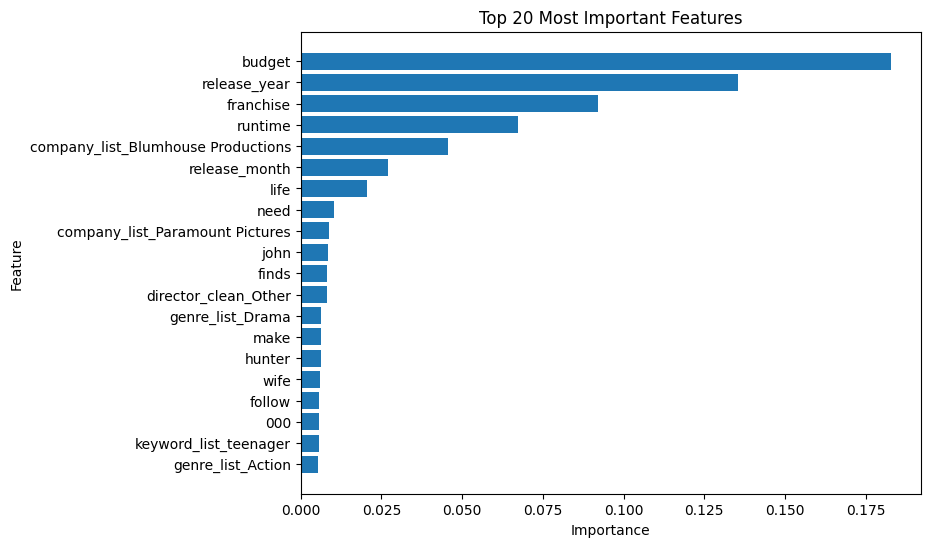

In [242]:
# ==========================================
# 40.2 Plot Top Features
# ==========================================

import matplotlib.pyplot as plt

top20 = feature_importance.head(20)

plt.figure(figsize=(8, 6))

plt.barh(
    top20["Feature"],
    top20["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")

plt.title("Top 20 Most Important Features")

plt.gca().invert_yaxis()

plt.show()

In [243]:
# ==========================================
# 40.3 Save Feature Importance
# ==========================================

feature_importance.to_csv(
    "../results/feature_importance.csv",
    index=False
)

print("Feature importance saved successfully!")

Feature importance saved successfully!


In [244]:
# ==========================================
# 41.1 Save Best Model
# ==========================================

import joblib

joblib.dump(
    rf,
    "../models/random_forest_model.pkl"
)

print("Random Forest model saved successfully!")

Random Forest model saved successfully!


In [245]:
# ==========================================
# 41.2 Save TF-IDF Vectorizer
# ==========================================

joblib.dump(
    tfidf,
    "../models/tfidf_vectorizer.pkl"
)

print("TF-IDF Vectorizer saved successfully!")

TF-IDF Vectorizer saved successfully!


In [246]:
# ==========================================
# 41.3 Save Feature Columns
# ==========================================

joblib.dump(
    X_final.columns.tolist(),
    "../models/feature_columns.pkl"
)

print("Feature columns saved successfully!")

Feature columns saved successfully!


In [247]:
# ==========================================
# 42. Save Final Feature Matrix
# ==========================================

X_final.to_csv(
    "../dataset/processed/X_final.csv",
    index=False
)

print("Final feature matrix saved successfully!")

Final feature matrix saved successfully!


In [248]:
# ==========================================
# Save Preprocessing Objects
# ==========================================

joblib.dump(
    genre_mlb,
    "../models/genre_encoder.pkl"
)

joblib.dump(
    keyword_mlb,
    "../models/keyword_encoder.pkl"
)

joblib.dump(
    company_mlb,
    "../models/company_encoder.pkl"
)

joblib.dump(
    country_mlb,
    "../models/country_encoder.pkl"
)

joblib.dump(
    language_mlb,
    "../models/language_encoder.pkl"
)

print("Preprocessing objects saved successfully!")

Preprocessing objects saved successfully!
